# Analisis Regresi OLS: Pengaruh Belanja Modal Pendidikan & Kesehatan terhadap IPM
## Studi Kasus Kota Jambi, 2014–2024

---

## Latar Belakang

Belanja modal pendidikan dan kesehatan merupakan investasi pemerintah daerah untuk meningkatkan
kualitas sumber daya manusia. Notebook ini menguji pengaruh kedua jenis belanja tersebut terhadap
**Indeks Pembangunan Manusia (IPM)** di **Kota Jambi** selama sebelas tahun (2014–2024),
menggunakan **regresi linier berganda (Ordinary Least Squares)**.

Kota Jambi dipilih karena model regresinya paling kuat di antara 97 kota pada dataset:
kedua variabel bebasnya **sama-sama signifikan** dan modelnya signifikan secara simultan.

## Model Penelitian

$$\text{IPM} = \beta_0 + \beta_1 \cdot \text{bm\_pendidikan} + \beta_2 \cdot \text{bm\_kesehatan} + \varepsilon$$

| Simbol | Variabel | Keterangan |
|---|---|---|
| $Y$ | `IPM` | Indeks Pembangunan Manusia |
| $X_1$ | `bm_pendidikan` | Belanja modal fungsi pendidikan |
| $X_2$ | `bm_kesehatan` | Belanja modal fungsi kesehatan |

## Hipotesis

- **H1**: Belanja modal pendidikan berpengaruh positif terhadap IPM.
- **H2**: Belanja modal kesehatan berpengaruh positif terhadap IPM.

## 1. Import Library

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image, display

# --- Deteksi lingkungan ---
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except Exception:
    DI_COLAB = False

try:
    import kaleido  # noqa: F401
    BISA_PNG = True
except Exception:
    BISA_PNG = False

# Renderer interaktif: grafik dapat diputar dan di-zoom (dipakai untuk grafik 3D).
RENDERER_INTERAKTIF = "colab" if DI_COLAB else "notebook_connected"

# Renderer default: PNG bila `kaleido` tersedia, agar grafik tetap terlihat
# saat notebook dibuka di GitHub. Bila tidak tersedia (mis. di Google Colab),
# otomatis memakai renderer interaktif.
pio.renderers.default = "png" if BISA_PNG else RENDERER_INTERAKTIF

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print(f"Lingkungan          : {'Google Colab' if DI_COLAB else 'Jupyter / lokal'}")
print(f"Ekspor PNG          : {'tersedia' if BISA_PNG else 'tidak tersedia'}")
print(f"Renderer default    : {pio.renderers.default}")
print(f"Renderer interaktif : {RENDERER_INTERAKTIF}")

Lingkungan          : Jupyter / lokal
Ekspor PNG          : tersedia
Renderer default    : png
Renderer interaktif : notebook_connected


## 2. Memuat Data

Dataset panel fiskal 97 kota dibaca dari repositori GitHub publik, lalu disaring
untuk **Kota Jambi** pada seluruh tahun yang tersedia.

In [2]:
URL_DATA = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"
KOTA_FOKUS = "Kota Jambi"   # ganti nama kota di sini bila ingin menganalisis kota lain

try:
    df = pd.read_csv(URL_DATA)
except Exception:
    df = pd.read_csv("data/dataset_fiskal_97_hipoFull.csv")

df = df[["Kota", "Tahun", "bm_pendidikan", "bm_kesehatan", "IPM"]].dropna()
df = df[df["Kota"] == KOTA_FOKUS].sort_values("Tahun").reset_index(drop=True)

print(f"Kota            : {KOTA_FOKUS}")
print(f"Rentang tahun   : {df['Tahun'].min()} - {df['Tahun'].max()}")
print(f"Jumlah observasi: {len(df)}")
df

Kota            : Kota Jambi
Rentang tahun   : 2014 - 2024
Jumlah observasi: 11


,Kota,Tahun,bm_pendidikan,bm_kesehatan,IPM
0,Kota Jambi,2014,129.2300,111.7800,78.7900
1,Kota Jambi,2015,92.3700,89.8900,74.9300
2,Kota Jambi,2016,189.2000,267.9500,70.6200
3,Kota Jambi,2017,284.0400,104.8000,83.4800
4,Kota Jambi,2018,224.0100,293.9700,64.6900
5,Kota Jambi,2019,192.5200,134.2200,68.0800
6,Kota Jambi,2020,74.2900,95.5300,68.1700
7,Kota Jambi,2021,203.7500,247.4200,67.8200
8,Kota Jambi,2022,297.5100,214.6800,74.6700
9,Kota Jambi,2023,85.0200,174.5500,65.2900


## 3. Statistik Deskriptif & Korelasi

In [3]:
kolom = ["bm_pendidikan", "bm_kesehatan", "IPM"]

print("Statistik Deskriptif:")
display(df[kolom].describe().round(2))

print("\nMatriks Korelasi:")
display(df[kolom].corr().round(3))

Statistik Deskriptif:


,bm_pendidikan,bm_kesehatan,IPM
count,11.0000,11.0000,11.0000
mean,177.4100,174.8800,70.9700
std,76.0000,73.4500,6.2500
min,74.2900,89.8900,64.1800
25%,110.8000,108.2900,66.5600
50%,189.2000,174.5500,68.1700
75%,213.8800,231.0500,74.8000
max,297.5100,293.9700,83.4800



Matriks Korelasi:


,bm_pendidikan,bm_kesehatan,IPM
bm_pendidikan,1.0000,0.4260,0.3030
bm_kesehatan,0.4260,1.0000,-0.5050
IPM,0.3030,-0.5050,1.0000


## 4. Estimasi Regresi OLS

Model diestimasi dengan `statsmodels`. Ringkasan output menampilkan koefisien,
*standard error*, statistik uji, serta ukuran kecocokan model (R² dan F-statistic).

In [4]:
model = smf.ols("IPM ~ bm_pendidikan + bm_kesehatan", data=df).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    IPM   R-squared:                       0.583
Model:                            OLS   Adj. R-squared:                  0.479
Method:                 Least Squares   F-statistic:                     5.602
Date:                Tue, 13 Oct 2026   Prob (F-statistic):             0.0301
Time:                        12:46:51   Log-Likelihood:                -30.433
No. Observations:                  11   AIC:                             66.87
Df Residuals:                       8   BIC:                             68.06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        73.2717      4.211     17.399

### Tabel Koefisien

In [5]:
tabel = pd.DataFrame({
    "Koefisien": model.params,
    "Std. Error": model.bse,
    "t-statistik": model.tvalues,
    "p-value": model.pvalues,
})
tabel["Signifikansi"] = np.where(
    model.pvalues < 0.01, "***",
    np.where(model.pvalues < 0.05, "**", np.where(model.pvalues < 0.10, "*", "")),
)
display(tabel.round(4))

print(f"R-squared      : {model.rsquared:.4f}")
print(f"Adj. R-squared : {model.rsquared_adj:.4f}")
print(f"F-statistic    : {model.fvalue:.4f}   (p-value = {model.f_pvalue:.4f})")

,Koefisien,Std. Error,t-statistik,p-value,Signifikansi
Intercept,73.2717,4.2112,17.3991,0.0000,***
bm_pendidikan,0.0521,0.0208,2.5095,0.0364,**
bm_kesehatan,-0.0660,0.0215,-3.0725,0.0153,**


R-squared      : 0.5834
Adj. R-squared : 0.4793
F-statistic    : 5.6018   (p-value = 0.0301)


## 5. Visualisasi

Grafik sebaran dengan garis regresi untuk melihat arah hubungan masing-masing variabel
bebas terhadap IPM, diagram batang nilai koefisien, serta **bidang regresi dalam ruang 3D**.

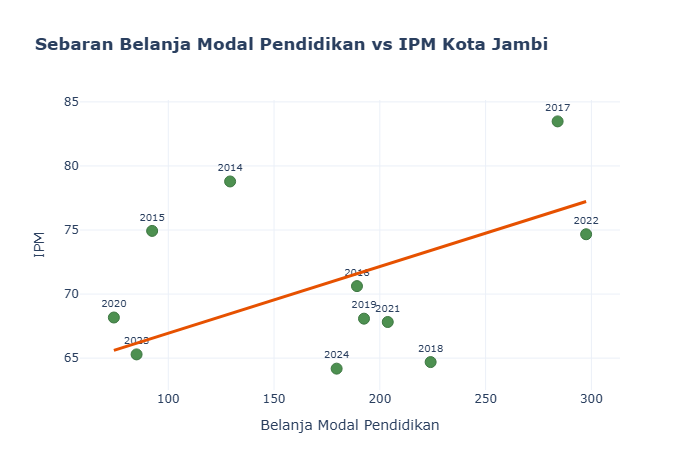

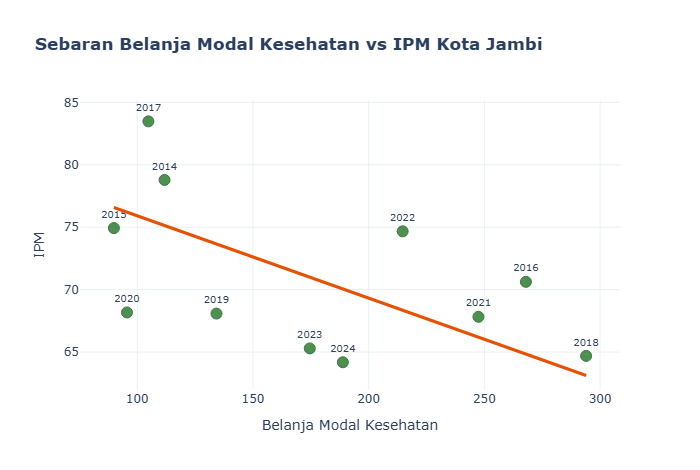

In [6]:
pasangan = [
    ("bm_pendidikan", "Belanja Modal Pendidikan"),
    ("bm_kesehatan", "Belanja Modal Kesehatan"),
]
rata_x1 = df["bm_pendidikan"].mean()
rata_x2 = df["bm_kesehatan"].mean()

for kolom_x, judul in pasangan:
    # garis regresi model berganda: variabel bebas lain ditahan pada nilai rata-ratanya
    x_garis = np.linspace(df[kolom_x].min(), df[kolom_x].max(), 100)
    if kolom_x == "bm_pendidikan":
        y_garis = (model.params["Intercept"]
                   + model.params["bm_pendidikan"] * x_garis
                   + model.params["bm_kesehatan"] * rata_x2)
    else:
        y_garis = (model.params["Intercept"]
                   + model.params["bm_pendidikan"] * rata_x1
                   + model.params["bm_kesehatan"] * x_garis)

    fig = px.scatter(
        df, x=kolom_x, y="IPM", text="Tahun", opacity=0.85,
        labels={kolom_x: judul, "IPM": "IPM"},
        title=f"<b>Sebaran {judul} vs IPM Kota Jambi</b>",
    )
    fig.update_traces(marker=dict(color="#2E7D32", size=11, line=dict(width=1, color="#1B5E20")),
                      textposition="top center", textfont=dict(size=10))
    fig.add_trace(go.Scatter(
        x=x_garis, y=y_garis, mode="lines",
        name="Garis Regresi", line=dict(color="#E65100", width=3),
    ))
    fig.update_layout(template="plotly_white", height=470, showlegend=False)
    fig.show()

### Koefisien Regresi OLS

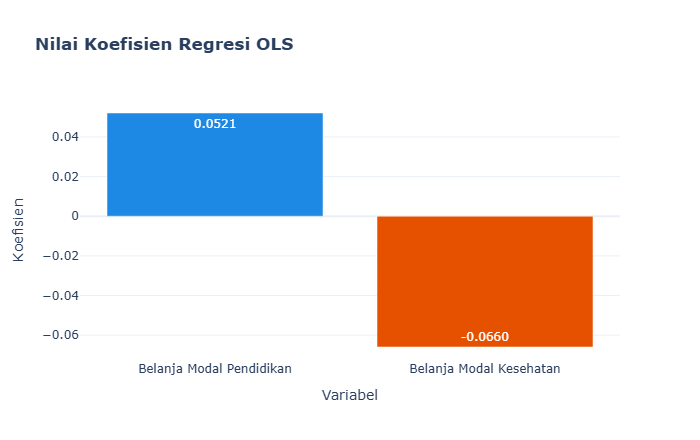

In [7]:
koef = pd.DataFrame({
    "Variabel": ["Belanja Modal Pendidikan", "Belanja Modal Kesehatan"],
    "Koefisien": [model.params["bm_pendidikan"], model.params["bm_kesehatan"]],
})

fig = px.bar(
    koef, x="Variabel", y="Koefisien", text_auto=".4f",
    color="Variabel", color_discrete_sequence=["#1E88E5", "#E65100"],
    title="<b>Nilai Koefisien Regresi OLS</b>",
)
fig.update_layout(template="plotly_white", height=440, showlegend=False)
fig.show()

### Visualisasi 3D: Bidang Regresi

Data aktual ditampilkan sebagai titik pada ruang 3D (belanja pendidikan, belanja kesehatan,
dan IPM) beserta **bidang regresi** yang dibentuk oleh model OLS.

Pratinjau statis (agar grafik tetap terlihat di GitHub):


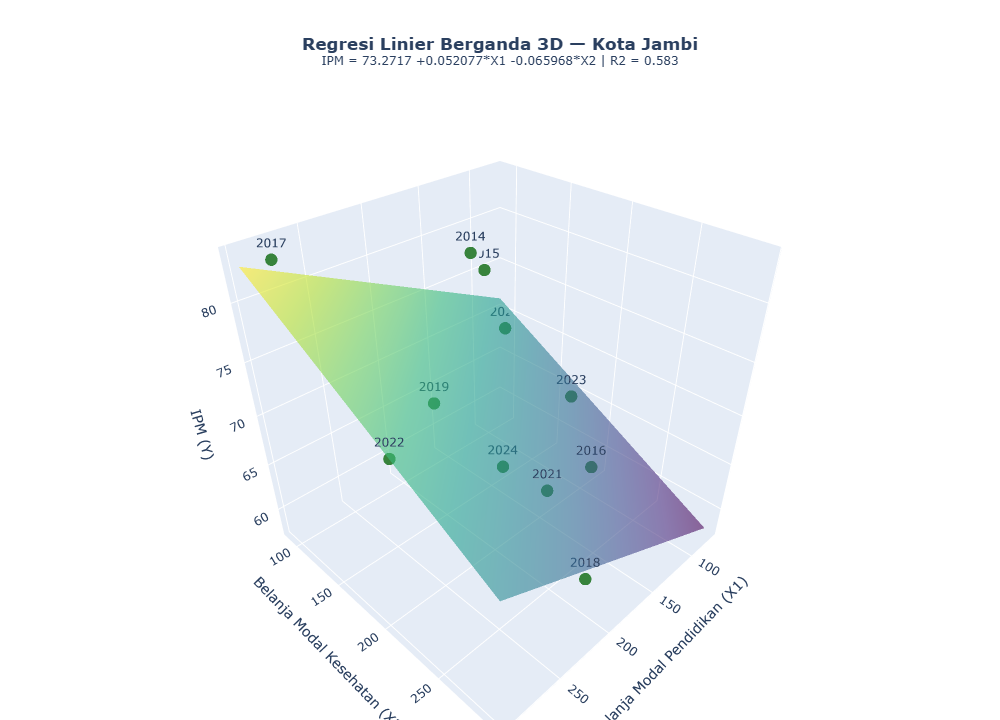

In [8]:
# Grid untuk bidang regresi
x1_grid = np.linspace(df["bm_pendidikan"].min(), df["bm_pendidikan"].max(), 25)
x2_grid = np.linspace(df["bm_kesehatan"].min(), df["bm_kesehatan"].max(), 25)

z_grid = np.array([
    [
        model.params["Intercept"]
        + model.params["bm_pendidikan"] * x1
        + model.params["bm_kesehatan"] * x2
        for x1 in x1_grid
    ]
    for x2 in x2_grid
])

persamaan = (
    f"IPM = {model.params['Intercept']:.4f} "
    f"{model.params['bm_pendidikan']:+.6f}*X1 "
    f"{model.params['bm_kesehatan']:+.6f}*X2"
)

fig3d = go.Figure()

# Data aktual
fig3d.add_trace(go.Scatter3d(
    x=df["bm_pendidikan"],
    y=df["bm_kesehatan"],
    z=df["IPM"],
    mode="markers+text",
    text=[str(t) for t in df["Tahun"]],
    textposition="top center",
    marker=dict(size=7, color="#2E7D32", opacity=0.95),
    name="Data Aktual",
    hovertemplate=(
        "Tahun %{text}<br>"
        "Belanja Pendidikan: %{x}<br>"
        "Belanja Kesehatan: %{y}<br>"
        "IPM: %{z}"
        "<extra></extra>"
    ),
))

# Bidang regresi
fig3d.add_trace(go.Surface(
    x=x1_grid,
    y=x2_grid,
    z=z_grid,
    opacity=0.60,
    colorscale="Viridis",
    showscale=False,
    name="Bidang Regresi",
    hovertemplate=(
        "Belanja Pendidikan: %{x:.2f}<br>"
        "Belanja Kesehatan: %{y:.2f}<br>"
        "Prediksi IPM: %{z:.2f}"
        "<extra></extra>"
    ),
))

fig3d.update_layout(
    title=dict(
        text=(
            "<b>Regresi Linier Berganda 3D — Kota Jambi</b><br>"
            f"<sup>{persamaan} | R2 = {model.rsquared:.3f}</sup>"
        ),
        x=0.5,
    ),
    scene=dict(
        xaxis=dict(title="Belanja Modal Pendidikan (X1)"),
        yaxis=dict(title="Belanja Modal Kesehatan (X2)"),
        zaxis=dict(title="IPM (Y)"),
    ),
    height=720,
    margin=dict(l=0, r=0, b=0, t=100),
    legend=dict(x=0.02, y=0.98),
)

# Grafik 3D ditampilkan INTERAKTIF agar bidang regresi dapat diputar dan di-zoom.
fig3d.show(renderer=RENDERER_INTERAKTIF)

# Pratinjau statis: grafik interaktif di atas tidak ikut tampil saat notebook
# dibuka di GitHub, sehingga gambar PNG berikut disertakan sebagai pelengkap.
if BISA_PNG:
    os.makedirs("images", exist_ok=True)
    try:
        # scale=1 (bukan 2) karena rendering 3D resolusi tinggi rawan gagal di browser headless
        fig3d.write_image("images/regresi_3d.png", width=1000, height=720, scale=1)
        print("Pratinjau statis (agar grafik tetap terlihat di GitHub):")
        display(Image(filename="images/regresi_3d.png"))
    except Exception as exc:
        print(f"Pratinjau statis 3D tidak dapat dibuat ({type(exc).__name__}).")
        print("Grafik 3D interaktif di atas tetap dapat digunakan.")

## 6. Kesimpulan

**Persamaan regresi terestimasi (Kota Jambi, 2014–2024, n = 11):**

$$\widehat{\text{IPM}} = 73{,}2717 + 0{,}0521 \cdot X_1 - 0{,}0660 \cdot X_2$$

| Variabel | Koefisien | Std. Error | t | p-value | Keputusan (alpha = 5%) |
|---|---|---|---|---|---|
| Konstanta | 73,2717 | 4,211 | 17,399 | < 0,001 | Signifikan |
| Belanja Modal Pendidikan | +0,0521 | 0,021 | 2,510 | 0,036 | **Signifikan (positif)** |
| Belanja Modal Kesehatan | −0,0660 | 0,021 | −3,072 | 0,015 | **Signifikan (negatif)** |

- **R² = 0,583** · **Adj. R² = 0,479** → model menjelaskan **58,3%** variasi IPM Kota Jambi.
- **F-statistic = 5,602 (p = 0,0301)** → secara simultan kedua variabel berpengaruh signifikan.

**Interpretasi:**

1. **H1 didukung** — belanja modal pendidikan berpengaruh **positif dan signifikan** terhadap IPM
   Kota Jambi. Setiap kenaikan satu satuan indeks belanja modal pendidikan meningkatkan IPM
   sebesar **0,0521 poin**.
2. **H2 tidak didukung** — belanja modal kesehatan berpengaruh **negatif dan signifikan**.
   Setiap kenaikan satu satuan indeks belanja modal kesehatan menurunkan IPM sebesar
   **0,0660 poin**. Hal ini tidak berarti belanja kesehatan merugikan IPM, melainkan dapat
   mencerminkan **alokasi berbasis kebutuhan** (tahun dengan capaian IPM rendah diikuti
   belanja modal kesehatan yang lebih besar) serta **efek jangka panjang** belanja modal
   yang baru terasa beberapa tahun kemudian.
3. **Daya penjelas model cukup kuat** (R² = 0,583) dibandingkan model gabungan seluruh
   97 kota (R² = 0,006), sehingga Kota Jambi menjadi studi kasus yang representatif untuk
   melihat hubungan belanja modal layanan dasar dengan IPM.

**Keterbatasan:** jumlah observasi terbatas (11 tahun), model belum mengontrol variabel lain
(mis. PAD, transfer pusat, kemiskinan, pengangguran), dan indikasi autokorelasi pada residual
perlu diperhatikan (Durbin-Watson = 0,705).